# Polynomial Regression in Python, Line by Line

**Regression Lab · Lesson 4** · College of Computer Studies, University of Technology Bahrain  
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version with hover-to-explain code: **https://saeedserwan.github.io/regression/code-polynomial.html**

A complete, runnable notebook that fits curves to car stopping-distance data: spotting the curve, engineering polynomial features, building a scikit-learn pipeline, choosing the degree with cross-validation and checking the danger of extrapolation. Every line is explained: hover over (or tap) a line to see what it does.

**You will learn to:**

1. Recognise a curved relationship from a residual plot
2. Create polynomial features with PolynomialFeatures
3. Build and fit a scikit-learn pipeline
4. Compare degrees with a test set and k-fold cross-validation
5. Plot fitted curves and see why extrapolation is risky

> Run the cells from top to bottom (Shift + Enter). After each code cell, a **Line by line** note explains what every line does.

## 1. Import the libraries

On top of the usual NumPy, pandas and Matplotlib, polynomial regression needs three extra scikit-learn tools:
**PolynomialFeatures** (creates $x^2, x^3, \dots$), **StandardScaler** (puts features on the same scale) and **make_pipeline** (chains steps together).

In [1]:
%config InlineBackend.figure_format = "retina"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True

**Line by line**

1. `%config InlineBackend.figure_format = "retina"`  
   A Jupyter setting (not Python): draw sharper plots on high-resolution screens.
2. `import numpy as np`  
   NumPy: arrays and maths.
3. `import pandas as pd`  
   pandas: tables (DataFrames).
4. `import matplotlib.pyplot as plt`  
   Matplotlib: charts.
5. `from sklearn.preprocessing import PolynomialFeatures, StandardScaler`  
   Feature tools: create powers of x, and rescale features to mean 0 and standard deviation 1.
6. `from sklearn.pipeline import make_pipeline`  
   Chains several steps (create features → scale → fit) into one model object.
7. `from sklearn.linear_model import LinearRegression`  
   Ordinary least squares, exactly as in the linear lesson.
8. `from sklearn.model_selection import train_test_split, KFold, cross_val_score`  
   Tools to split data and run k-fold cross-validation.
9. `from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score`  
   Evaluation metrics.
10. `plt.rcParams["figure.figsize"] = (7, 4.5)`  
   Default chart size in inches.
11. `plt.rcParams["axes.grid"] = True`  
   Light grid lines on every chart.

## 2. Load the dataset

**24 test drives**: the car's speed (km/h) and the distance it needed to stop (m). Physics tells us braking distance grows with the *square* of speed, so we expect a curve.

In [2]:
url = "https://raw.githubusercontent.com/SaeedSerwan/regression/main/data/speed_stopping_distance.csv"
df = pd.read_csv(url)
df.columns = ["speed", "distance"]
df = df.sort_values("speed").reset_index(drop=True)
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (24, 2)


,speed,distance
0,25,22.2
1,30,12.8
2,32,23.7
3,33,16.6
4,36,26.2


**Line by line**

1. `url = "https://raw.githubusercontent.com/SaeedSerwan/regression/main/data/speed_stopping_distance.csv"`  
   Location of the CSV file in the course repository.
2. `df = pd.read_csv(url)`  
   Load it into a DataFrame.
3. `df.columns = ["speed", "distance"]`  
   Short column names: speed (km/h) and stopping distance (m).
4. `df = df.sort_values("speed").reset_index(drop=True)`  
   Sort the rows by speed (handy for reading the table) and renumber them 0, 1, 2, …
5. `print("Rows and columns:", df.shape)`  
   24 rows, 2 columns.
6. `df.head()`  
   Show the first 5 rows.

## 3. Look at the data

In [3]:
df.describe().round(1)

,speed,distance
count,24.0,24.0
mean,67.5,60.1
std,30.8,39.1
min,25.0,12.8
25%,46.5,27.9
50%,60.5,45.9
75%,93.2,89.6
max,130.0,151.4


**Line by line**

1. `df.describe().round(1)`  
   Summary statistics: count, mean, spread and range of each column.

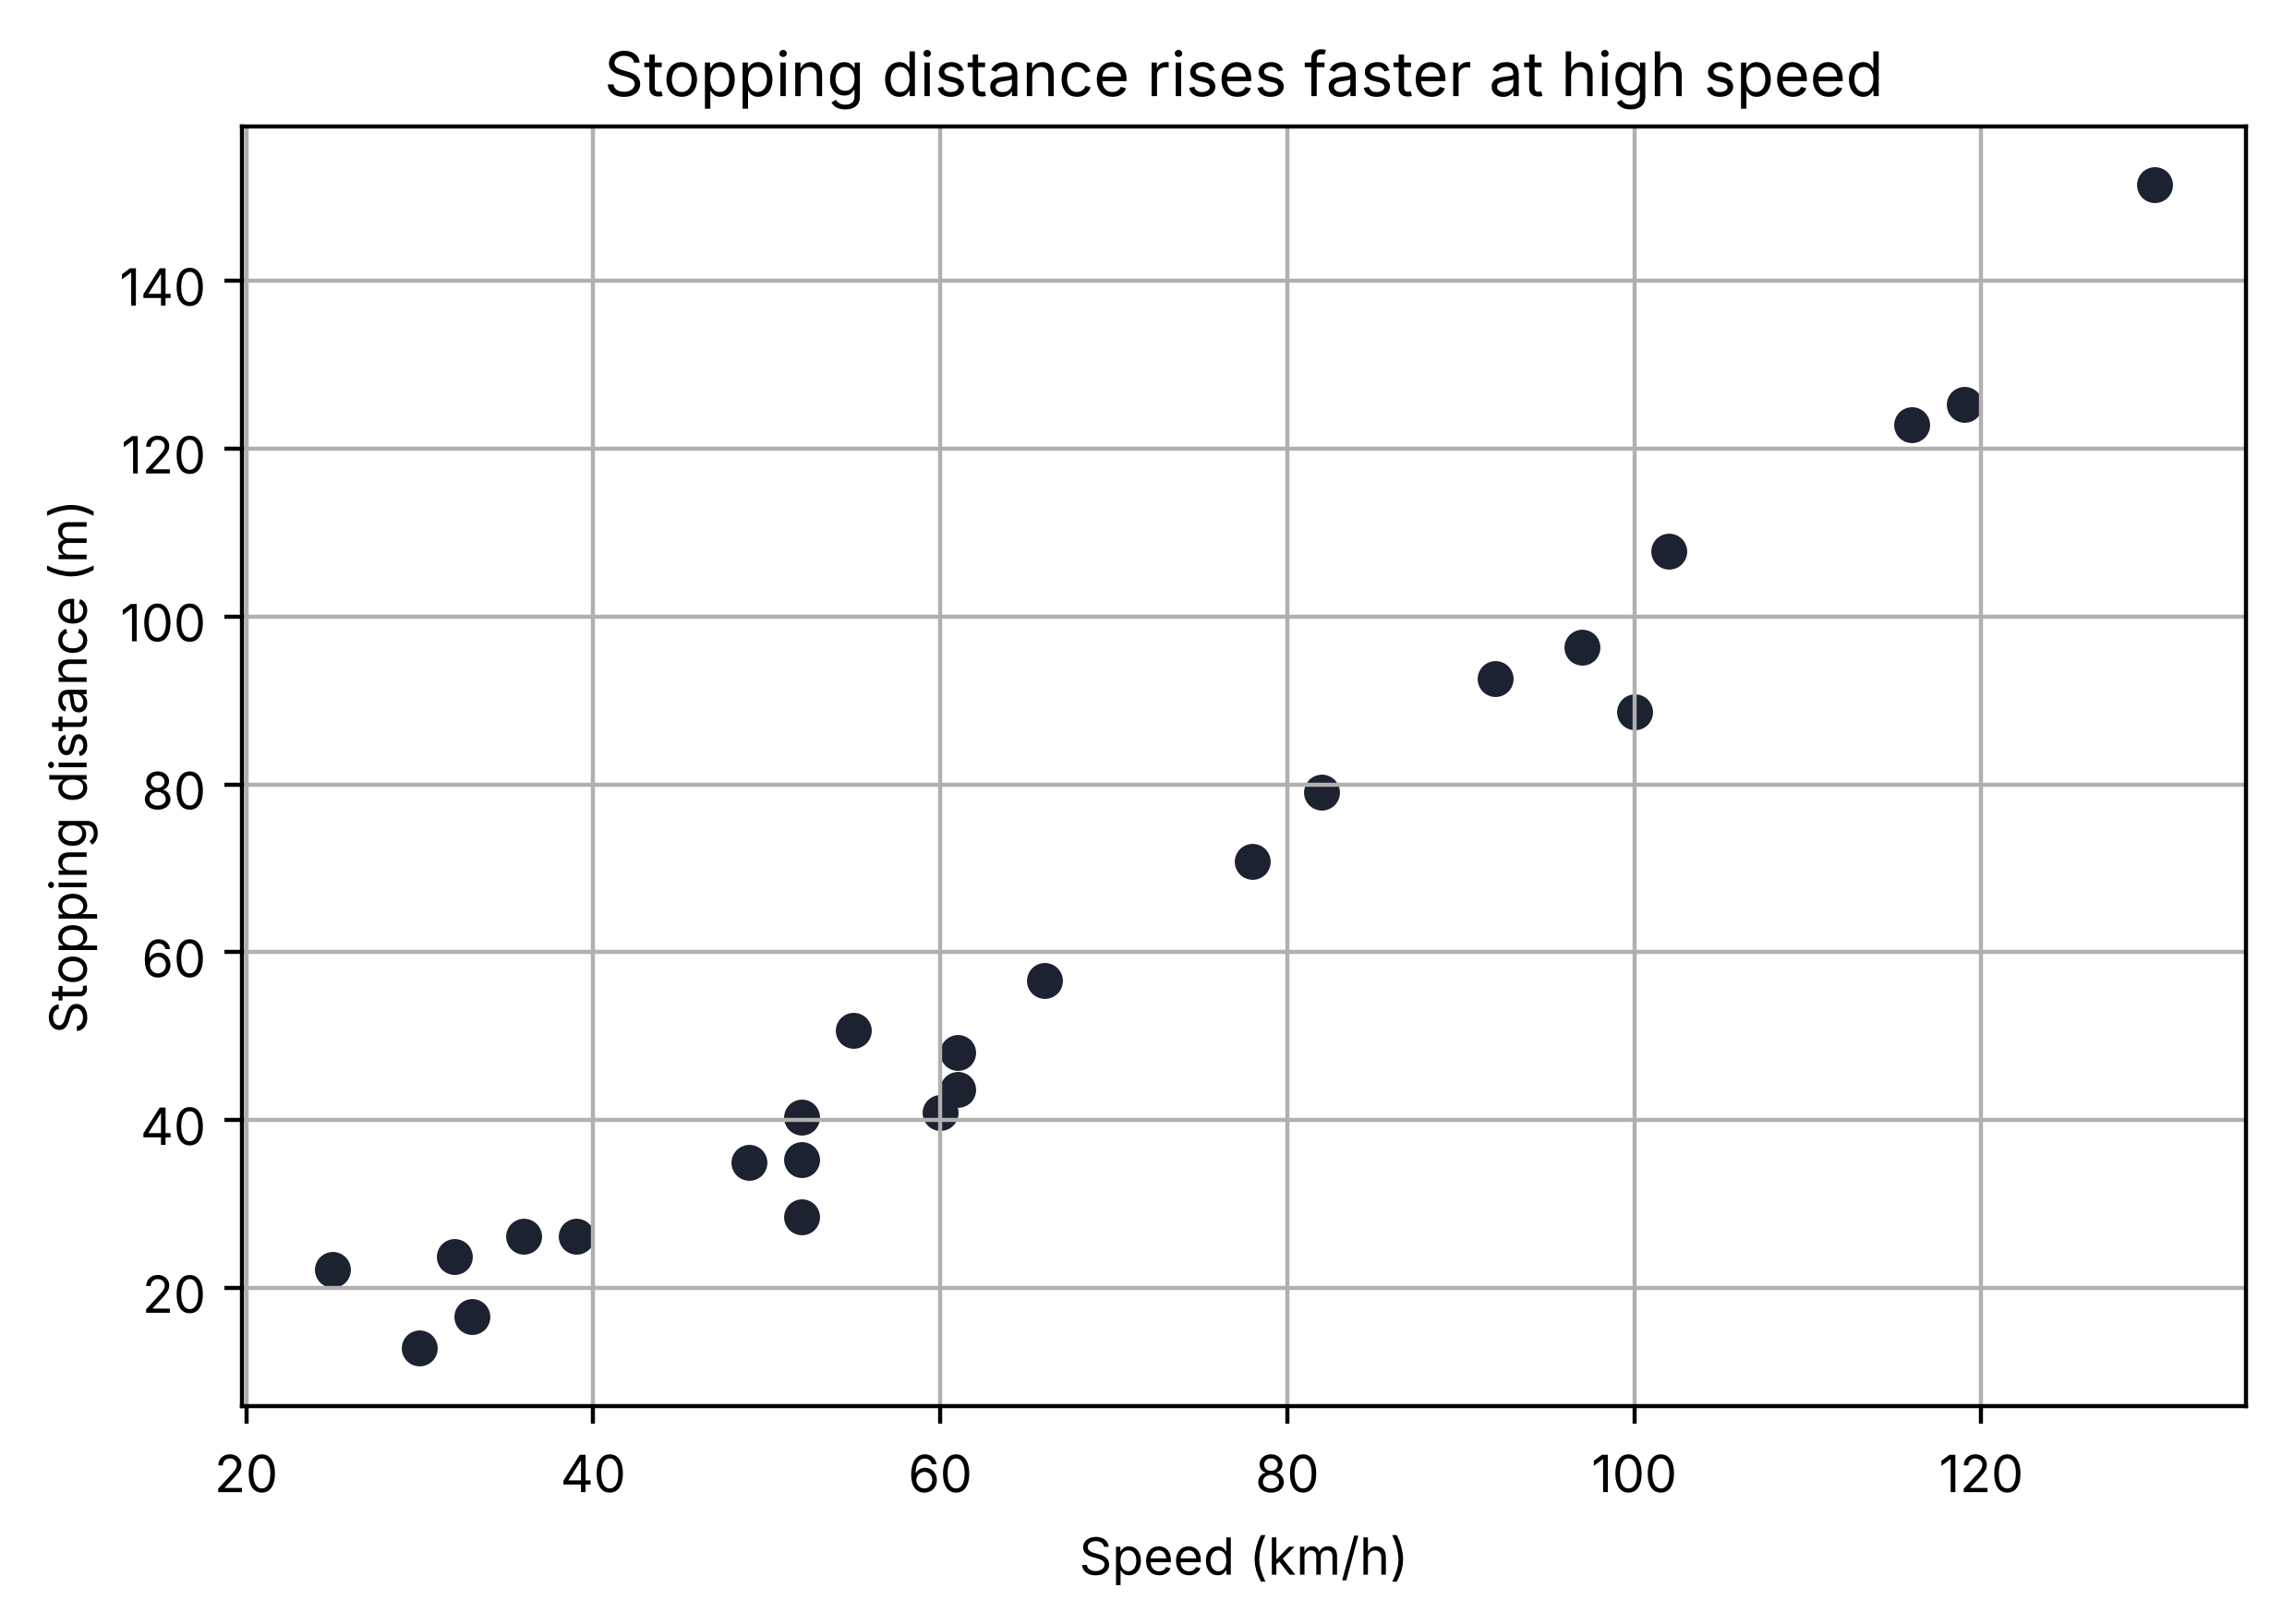

In [4]:
plt.scatter(df["speed"], df["distance"], color="#1c2230")
plt.xlabel("Speed (km/h)")
plt.ylabel("Stopping distance (m)")
plt.title("Stopping distance rises faster at high speed")
plt.show()

**Line by line**

1. `plt.scatter(df["speed"], df["distance"], color="#1c2230")`  
   One dot per test drive.
2. `plt.xlabel("Speed (km/h)")` …  
   Axis labels with units.
3. `plt.title("Stopping distance rises faster at high speed")`  
   A title stating the takeaway.
4. `plt.show()`  
   Display the chart.

## 4. Try a straight line first

Always start with the simplest model. Then check its **residuals** to see whether it missed a pattern.

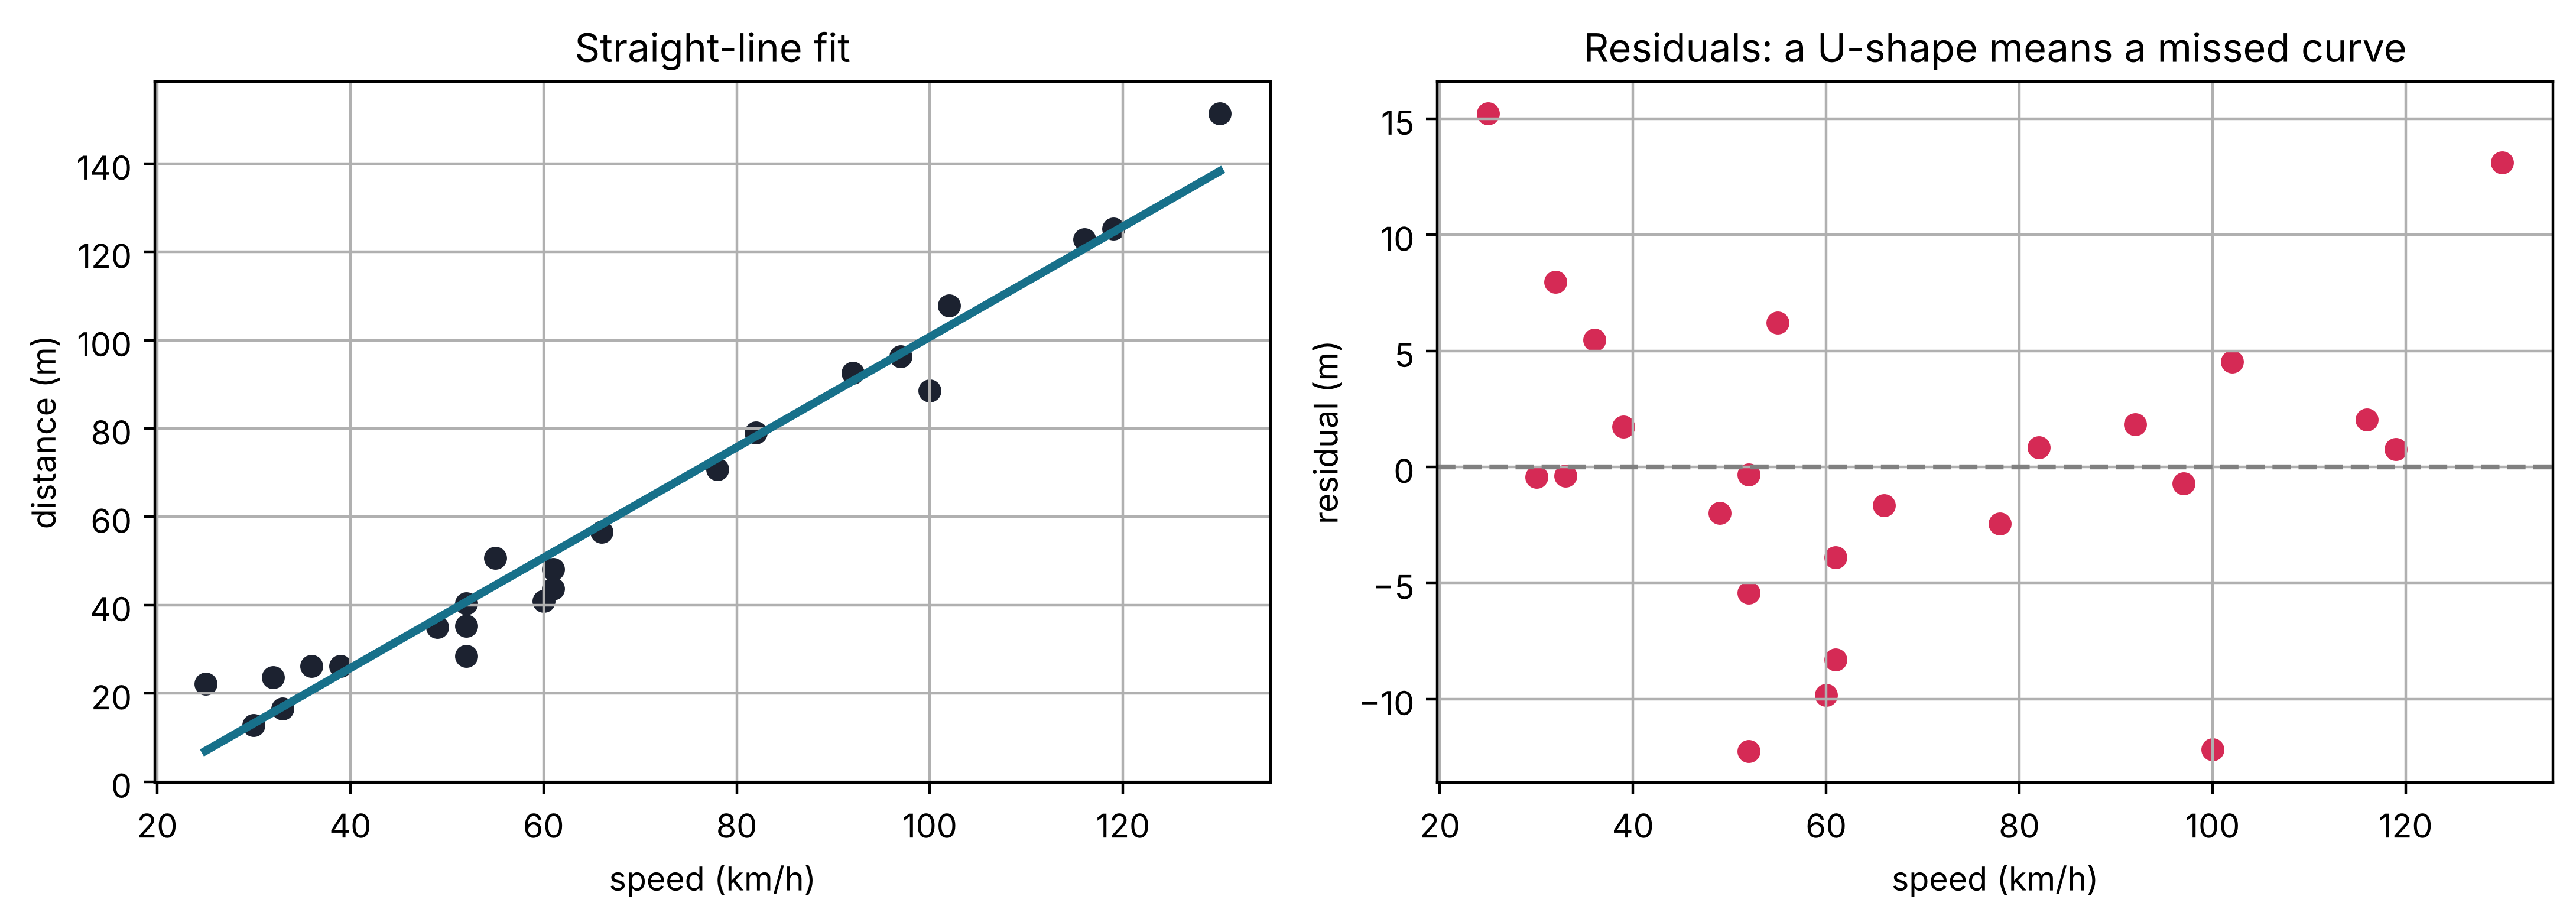

In [5]:
X = df[["speed"]]
y = df["distance"]

line = LinearRegression().fit(X, y)
line_resid = y - line.predict(X)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X["speed"], y, color="#1c2230")
axes[0].plot(X["speed"], line.predict(X), color="#17708a", linewidth=2.5)
axes[0].set(title="Straight-line fit", xlabel="speed (km/h)", ylabel="distance (m)")
axes[1].scatter(X["speed"], line_resid, color="#d52a55")
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set(title="Residuals: a U-shape means a missed curve", xlabel="speed (km/h)", ylabel="residual (m)")
plt.tight_layout()
plt.show()

**Line by line**

1. `X = df[["speed"]]`  
   Feature table (2-D, as scikit-learn requires).
2. `y = df["distance"]`  
   Target column.
3. `line = LinearRegression().fit(X, y)`  
   Create and train a straight-line model in one line (`fit` returns the model itself).
4. `line_resid = y - line.predict(X)`  
   Residuals of the straight line.
5. `fig, axes = plt.subplots(1, 2, figsize=(11, 4))`  
   Two panels: the fit, and its residuals.
6. `axes[0].scatter(X["speed"], y, color="#1c2230")`  
   Left: the data…
7. `axes[0].plot(X["speed"], line.predict(X), color="#17708a", linewidth=2.5)`  
   …and the fitted straight line (the rows are sorted, so the line draws cleanly).
8. `axes[0].set(title="Straight-line fit", xlabel="speed (km/h)", ylabel="distance (m)")`  
   Labels for the left panel.
9. `axes[1].scatter(X["speed"], line_resid, color="#d52a55")`  
   Right: residual for each test drive.
10. `axes[1].axhline(0, color="grey", linestyle="--")`  
   Zero-error reference line.
11. `axes[1].set(title="Residuals: a U-shape means a missed curve", xlabel="speed (km/h)", ylabel="residual (m)")`  
   Labels for the right panel.
12. `plt.tight_layout()`  
   Tidy spacing.
13. `plt.show()`  
   Display.

The residuals are **positive at both ends and negative in the middle**: a U-shape. The straight line is too low at slow and fast speeds and too high in between. We need a curve.

## 5. Create polynomial features

Polynomial regression is linear regression on **extra columns** built from $x$: $x^2$, $x^3$, and so on.
`PolynomialFeatures` builds them for us. Let's look at what it produces for degree 2.

In [6]:
poly = PolynomialFeatures(degree=2, include_bias=False)
features = poly.fit_transform(X.head())
pd.DataFrame(features, columns=poly.get_feature_names_out())

,speed,speed^2
0,25.0,625.0
1,30.0,900.0
2,32.0,1024.0
3,33.0,1089.0
4,36.0,1296.0


**Line by line**

1. `poly = PolynomialFeatures(degree=2, include_bias=False)`  
   Make features up to x². `include_bias=False` skips the column of 1s, because LinearRegression adds its own intercept.
2. `features = poly.fit_transform(X.head())`  
   Transform the first 5 rows: each speed becomes [speed, speed²].
3. `pd.DataFrame(features, columns=poly.get_feature_names_out())`  
   Show the result as a table, with the generated column names.

The model is now $\hat y = \beta_0 + \beta_1\,\text{speed} + \beta_2\,\text{speed}^2$. It is still *linear in the coefficients* $\beta$, so ordinary least squares fits it.

## 6. Fit a degree-2 model

A **pipeline** joins the feature step and the model into one object, so `fit` and `predict` apply both steps automatically.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=18)

quad = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression())
quad.fit(X_train, y_train)

lr = quad.named_steps["linearregression"]
b0, b1, b2 = lr.intercept_, lr.coef_[0], lr.coef_[1]
print(f"distance = {b0:.3f} + {b1:.4f}·speed + {b2:.6f}·speed²")

distance = -5.281 + 0.6120·speed + 0.004428·speed²


**Line by line**

1. `X_train, X_test, y_train, y_test = train_test_split(`  
   Hold out 25 % of the test drives for testing.
2. `X, y, test_size=0.25, random_state=18)`  
   A fixed `random_state` makes the split reproducible.
3. `quad = make_pipeline(` …  
   Build the pipeline: step 1 creates [speed, speed²], step 2 fits least squares on them.
4. `quad.fit(X_train, y_train)`  
   Train the whole pipeline on the training data.
5. `lr = quad.named_steps["linearregression"]`  
   Reach inside the pipeline to get the fitted LinearRegression step.
6. `b0, b1, b2 = lr.intercept_, lr.coef_[0], lr.coef_[1]`  
   The intercept and the two coefficients (for speed and speed²).
7. `print(f"distance = {b0:.3f} + {b1:.4f}·speed + {b2:.6f}·speed²")`  
   Print the fitted curve's equation.

The small positive coefficient on $\text{speed}^2$ is the curvature: at high speeds it dominates, just as the physics predicts.

## 7. Compare against the straight line on the test set

In [8]:
def evaluate(model, name):
    pred = model.predict(X_test)
    return {"model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R²": r2_score(y_test, pred)}

straight = LinearRegression().fit(X_train, y_train)
comparison = pd.DataFrame([evaluate(straight, "degree 1 (line)"),
                           evaluate(quad, "degree 2 (quadratic)")])
comparison.round(3)

,model,MAE,RMSE,R²
0,degree 1 (line),5.789,7.856,0.948
1,degree 2 (quadratic),4.025,4.981,0.979


**Line by line**

1. `def evaluate(model, name):`  
   A reusable function that scores an already-trained model on the test set.
2. `pred = model.predict(X_test)`  
   Predictions for the held-out test drives.
3. `return {"model": name,` …  
   Return a dictionary of metrics (one row of a results table).
4. `straight = LinearRegression().fit(X_train, y_train)`  
   A straight line trained on the same training data, for a fair comparison.
5. `comparison = pd.DataFrame([evaluate(straight, "degree 1 (line)"),` …  
   Evaluate both models and stack the results into one table.
6. `comparison.round(3)`  
   Display, rounded to 3 decimals.

Lower MAE and RMSE and a higher R² on **unseen** data: the curve is genuinely better, not just more flexible.

> **But only 6 cars are in the test set.** With so few, the verdict depends on *which* cars happen to land there (try `random_state=1` in step 6 and the line wins!).
> That is why step 9 uses cross-validation, which tests on every car once.

## 8. What happens with more flexibility?

Let's plot curves of several degrees. Higher degrees can wiggle to chase individual points.

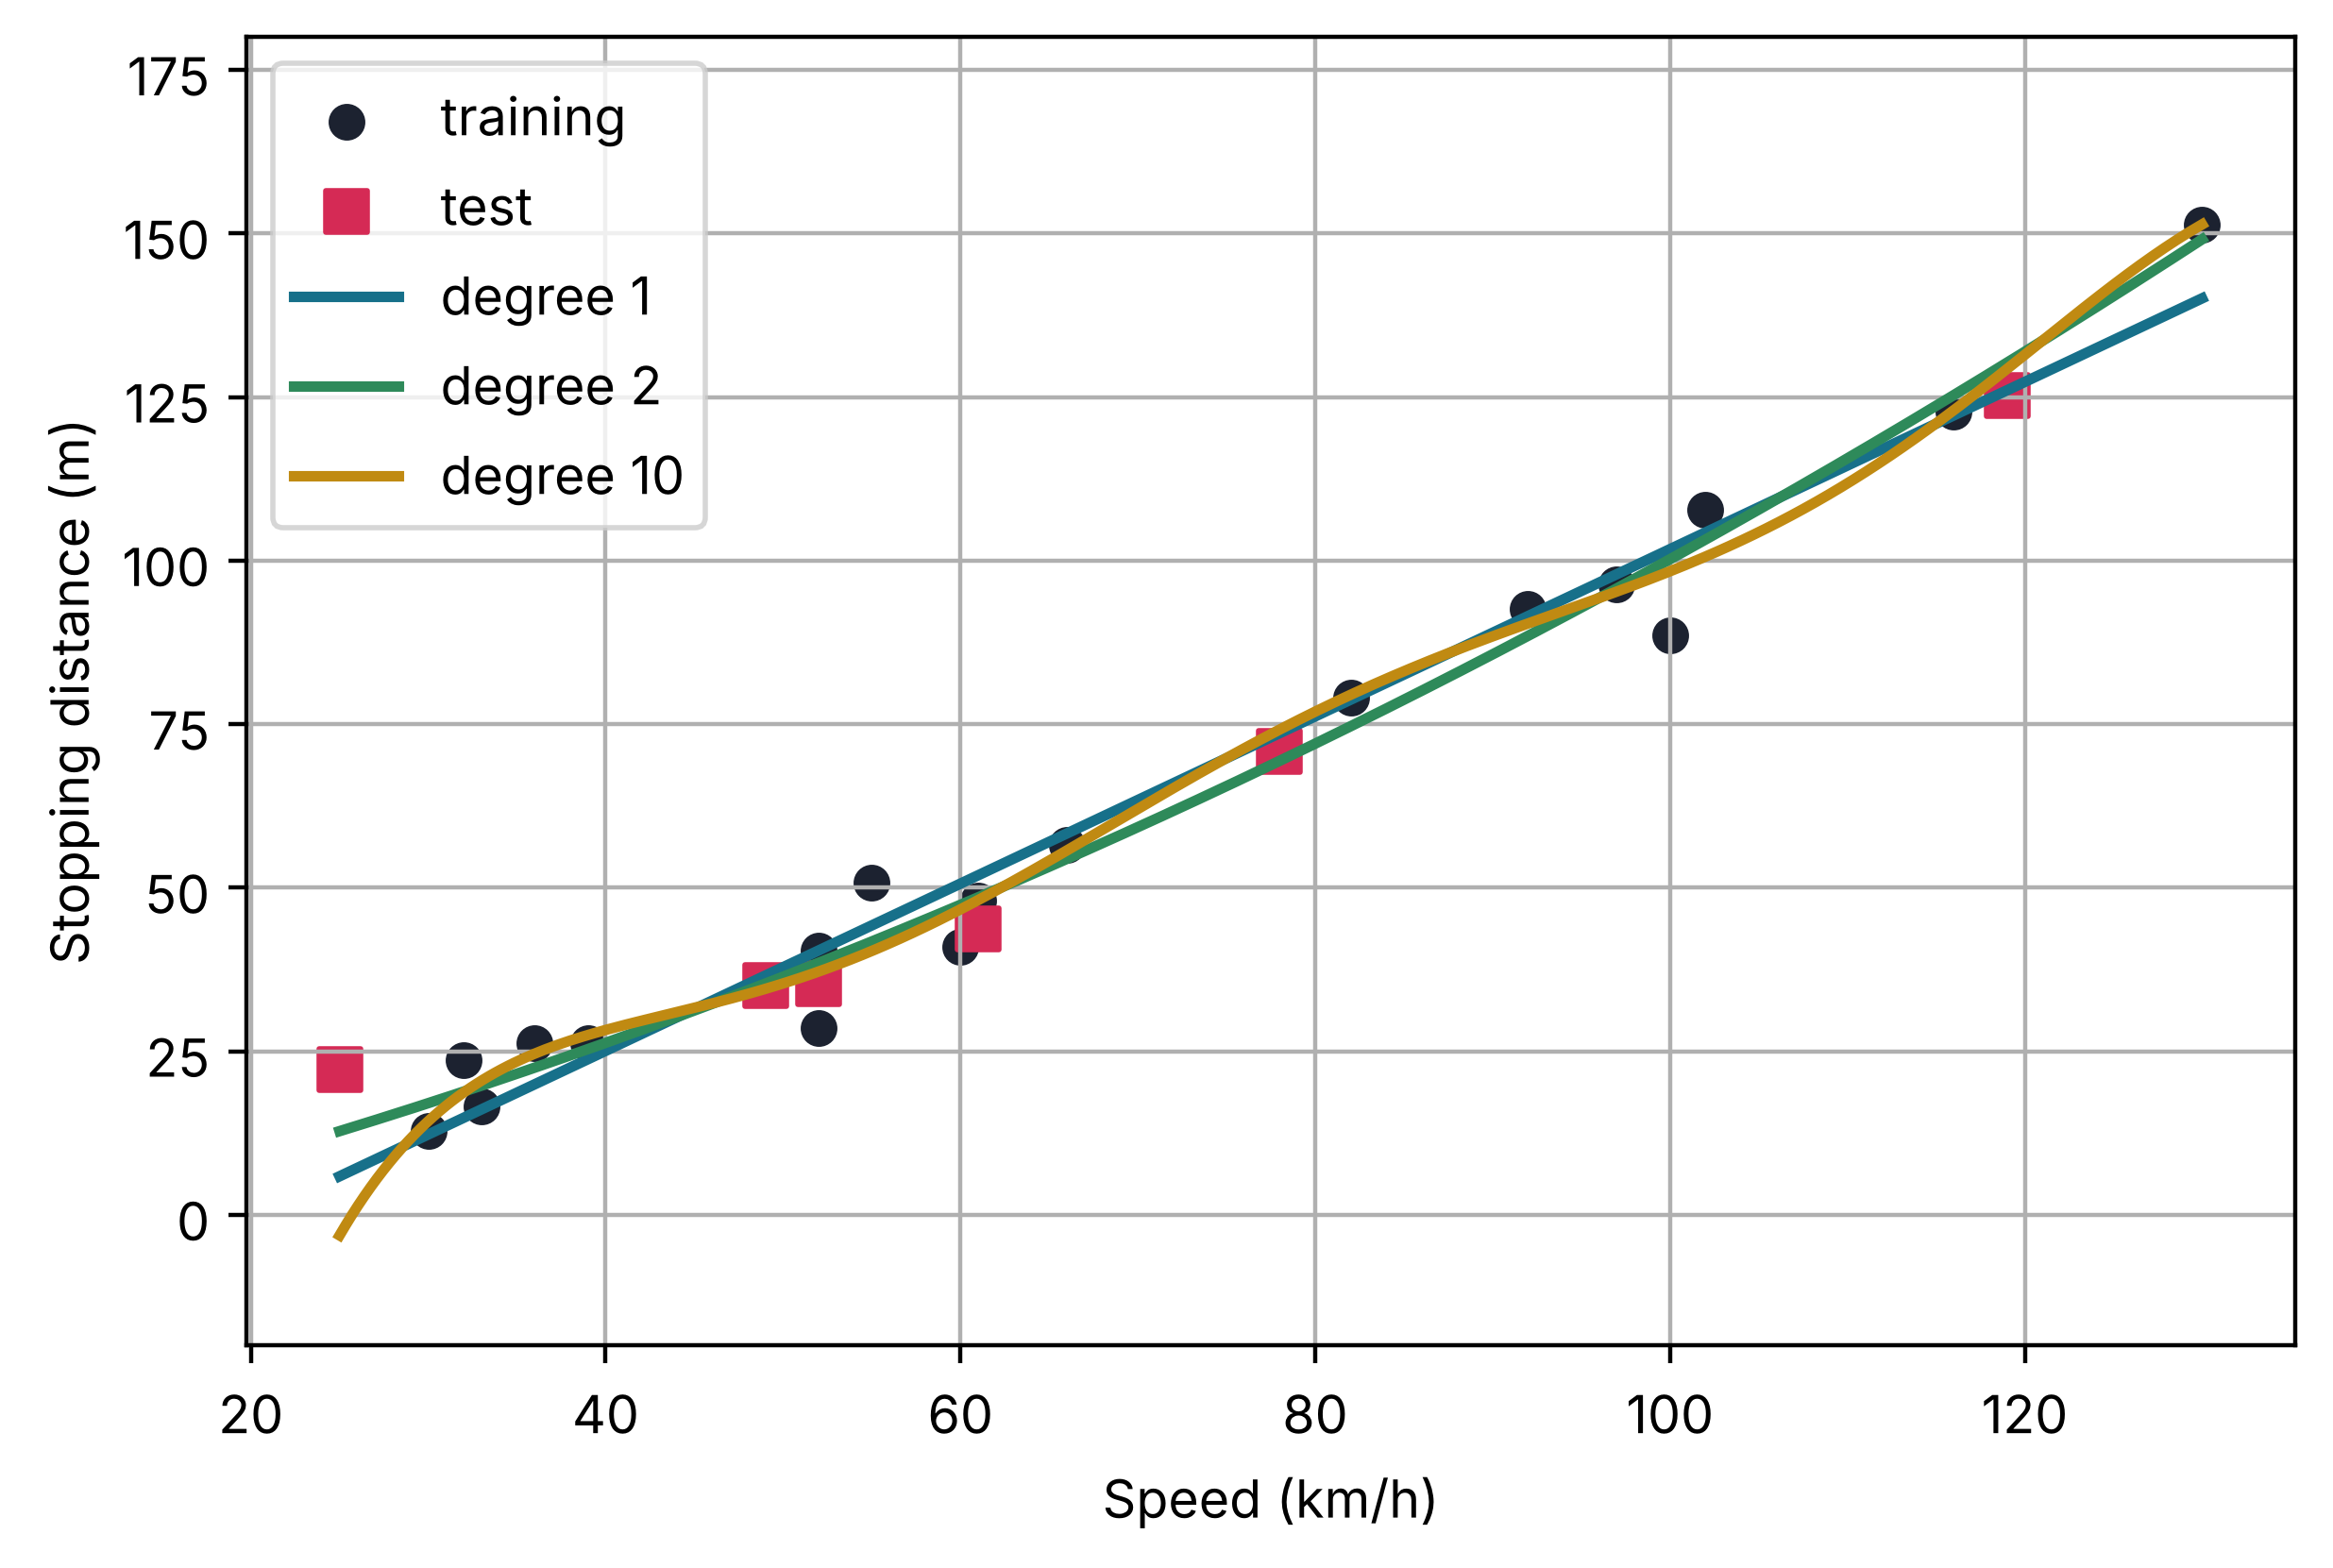

In [9]:
grid = pd.DataFrame({"speed": np.linspace(X["speed"].min(), X["speed"].max(), 300)})

plt.scatter(X_train["speed"], y_train, color="#1c2230", label="training")
plt.scatter(X_test["speed"], y_test, color="#d52a55", marker="s", s=60, label="test")
for degree, colour in [(1, "#17708a"), (2, "#2e8a5a"), (10, "#c08a12")]:
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                          StandardScaler(),
                          LinearRegression())
    model.fit(X_train, y_train)
    plt.plot(grid["speed"], model.predict(grid), color=colour, linewidth=2, label=f"degree {degree}")
plt.ylim(-20, 180)
plt.xlabel("Speed (km/h)")
plt.ylabel("Stopping distance (m)")
plt.legend()
plt.show()

**Line by line**

1. `grid = pd.DataFrame({"speed": np.linspace(X["speed"].min(), X["speed"].max(), 300)})`  
   300 evenly spaced speeds, to draw smooth curves.
2. `plt.scatter(X_train["speed"], y_train, color="#1c2230", label="training")`  
   Training data as dark dots.
3. `plt.scatter(X_test["speed"], y_test, color="#d52a55", marker="s", s=60, label="test")`  
   Test data as red squares.
4. `for degree, colour in [(1, "#17708a"), (2, "#2e8a5a"), (10, "#c08a12")]:`  
   Loop over three degrees, each with its own colour.
5. `model = make_pipeline(PolynomialFeatures(degree, include_bias=False),`  
   Features up to x^degree…
6. `StandardScaler(),`  
   …rescaled so huge powers like speed¹⁰ stay numerically manageable…
7. `LinearRegression())`  
   …then least squares.
8. `model.fit(X_train, y_train)`  
   Train this degree.
9. `plt.plot(grid["speed"], model.predict(grid), color=colour, linewidth=2, label=f"degree {degree}")`  
   Draw its curve.
10. `plt.ylim(-20, 180)`  
   Fix the y-range so a wild curve doesn't squash the plot.
11. `plt.xlabel("Speed (km/h)")` …  
   Labels, key and display.

The degree-10 curve bends to pass close to the training points: it is **overfitting** and will predict new cars badly.

## 9. Choose the degree with cross-validation

One test split is a small, noisy sample. **5-fold cross-validation** splits the data into 5 parts, trains on 4 and tests on the 5th, five times over, and averages the error.

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for degree in range(1, 11):
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                          StandardScaler(), LinearRegression())
    scores = cross_val_score(model, X, y, cv=cv,
                             scoring="neg_root_mean_squared_error")
    train_rmse = np.sqrt(mean_squared_error(y, model.fit(X, y).predict(X)))
    rows.append({"degree": degree, "train RMSE": train_rmse, "CV RMSE": -scores.mean()})

cv_table = pd.DataFrame(rows).set_index("degree")
cv_table.round(2)

,train RMSE,CV RMSE
degree,,
1,6.74,7.56
2,5.10,5.64
3,5.05,6.12
4,4.70,5.50
5,4.68,7.30
6,4.68,8.89
7,4.52,14.23
8,4.55,16.20
9,4.58,18.32


**Line by line**

1. `cv = KFold(n_splits=5, shuffle=True, random_state=0)`  
   Define the 5 folds (shuffled once, reproducibly).
2. `rows = []`  
   We will collect one result per degree in this list.
3. `for degree in range(1, 11):`  
   Try degrees 1 to 10.
4. `model = make_pipeline(PolynomialFeatures(degree, include_bias=False),` …  
   Same pipeline as before.
5. `scores = cross_val_score(model, X, y, cv=cv,` …  
   Train and test 5 times. scikit-learn returns *negative* RMSE (it always maximises scores)…
6. `train_rmse = np.sqrt(mean_squared_error(y, model.fit(X, y).predict(X)))`  
   Training error on all the data, for comparison.
7. `rows.append({"degree": degree, "train RMSE": train_rmse, "CV RMSE": -scores.mean()})`  
   …so we flip the sign back and store the average.
8. `cv_table = pd.DataFrame(rows).set_index("degree")`  
   Turn the list into a table indexed by degree.
9. `cv_table.round(2)`  
   Display it.

Lowest CV RMSE = 5.50 m  →  chosen degree = 2


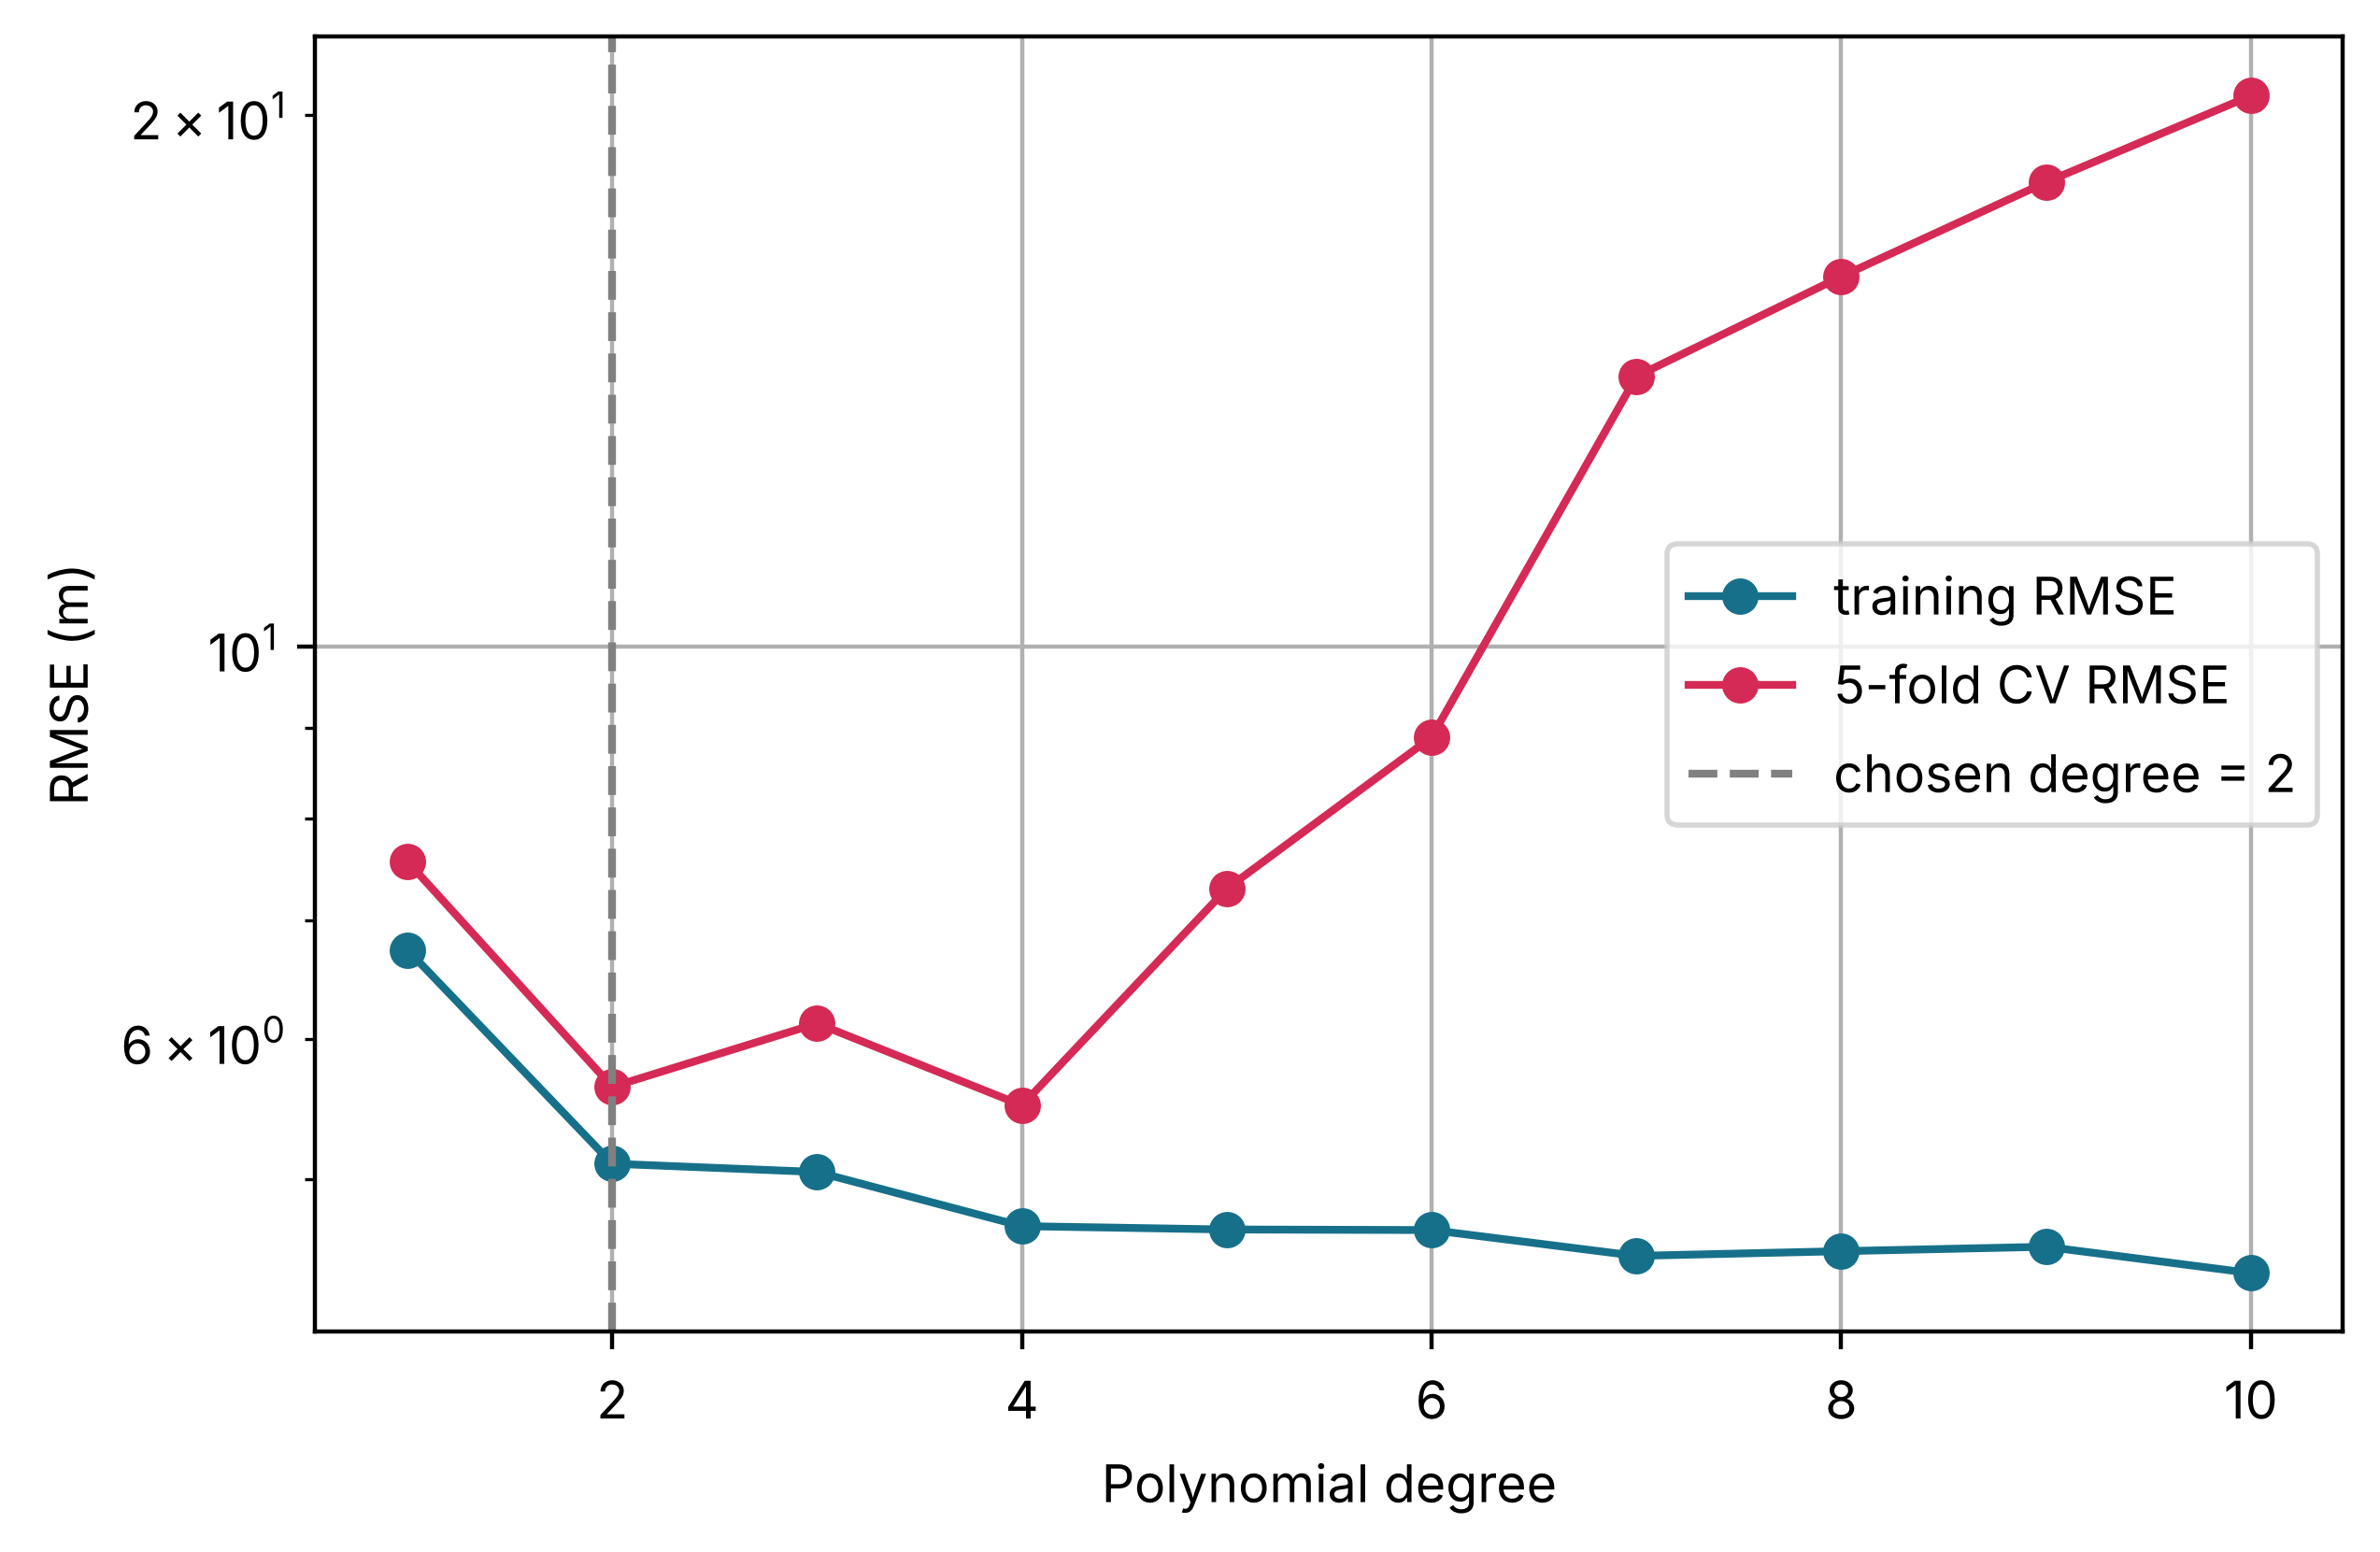

In [11]:
best = cv_table["CV RMSE"].min()
chosen = cv_table[cv_table["CV RMSE"] <= 1.05 * best].index.min()
print(f"Lowest CV RMSE = {best:.2f} m  →  chosen degree = {chosen}")

plt.plot(cv_table.index, cv_table["train RMSE"], "o-", color="#17708a", label="training RMSE")
plt.plot(cv_table.index, cv_table["CV RMSE"], "o-", color="#d52a55", label="5-fold CV RMSE")
plt.axvline(chosen, color="grey", linestyle="--", label=f"chosen degree = {chosen}")
plt.yscale("log")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (m)")
plt.legend()
plt.show()

**Line by line**

1. `best = cv_table["CV RMSE"].min()`  
   The lowest cross-validated error of any degree.
2. `chosen = cv_table[cv_table["CV RMSE"] <= 1.05 * best].index.min()`  
   Rule of thumb: pick the SIMPLEST degree whose CV error is within 5 % of the best.
3. `print(f"Lowest CV RMSE = {best:.2f} m  →  chosen degree = {chosen}")`  
   Report the choice.
4. `plt.plot(cv_table.index, cv_table["train RMSE"], "o-", color="#17708a", label="training RMSE")`  
   Training error by degree ("o-" = dots joined by lines).
5. `plt.plot(cv_table.index, cv_table["CV RMSE"], "o-", color="#d52a55", label="5-fold CV RMSE")`  
   Cross-validated error by degree.
6. `plt.axvline(chosen, color="grey", linestyle="--", label=f"chosen degree = {chosen}")`  
   Mark the chosen degree.
7. `plt.yscale("log")`  
   Log scale, because the CV error explodes for high degrees.
8. `plt.xlabel("Polynomial degree")` …  
   Labels, key and display.

Training error **always** falls as the degree rises, but cross-validated error falls and then climbs. That U-shape is the **bias–variance trade-off**. Choosing the simplest model that is close to the best protects us from reading too much into small differences.

## 10. Final model and predictions

In [12]:
final = make_pipeline(PolynomialFeatures(chosen, include_bias=False),
                      StandardScaler(), LinearRegression())
final.fit(X, y)

new_speeds = pd.DataFrame({"speed": [50, 90, 120]})
new_speeds["predicted distance (m)"] = final.predict(new_speeds).round(1)
new_speeds

,speed,predicted distance (m)
0,50,36.5
1,90,84.4
2,120,131.3


**Line by line**

1. `final = make_pipeline(PolynomialFeatures(chosen, include_bias=False),` …  
   Rebuild the pipeline with the chosen degree…
2. `final.fit(X, y)`  
   …and train it on ALL the data, now that the degree is decided.
3. `new_speeds = pd.DataFrame({"speed": [50, 90, 120]})`  
   Three speeds we want predictions for.
4. `new_speeds["predicted distance (m)"] = final.predict(new_speeds).round(1)`  
   Predict and add as a new column.
5. `new_speeds`  
   Display.

## 11. The danger of extrapolation

Our data covers about 25–130 km/h. What do different models say at **200 km/h**?

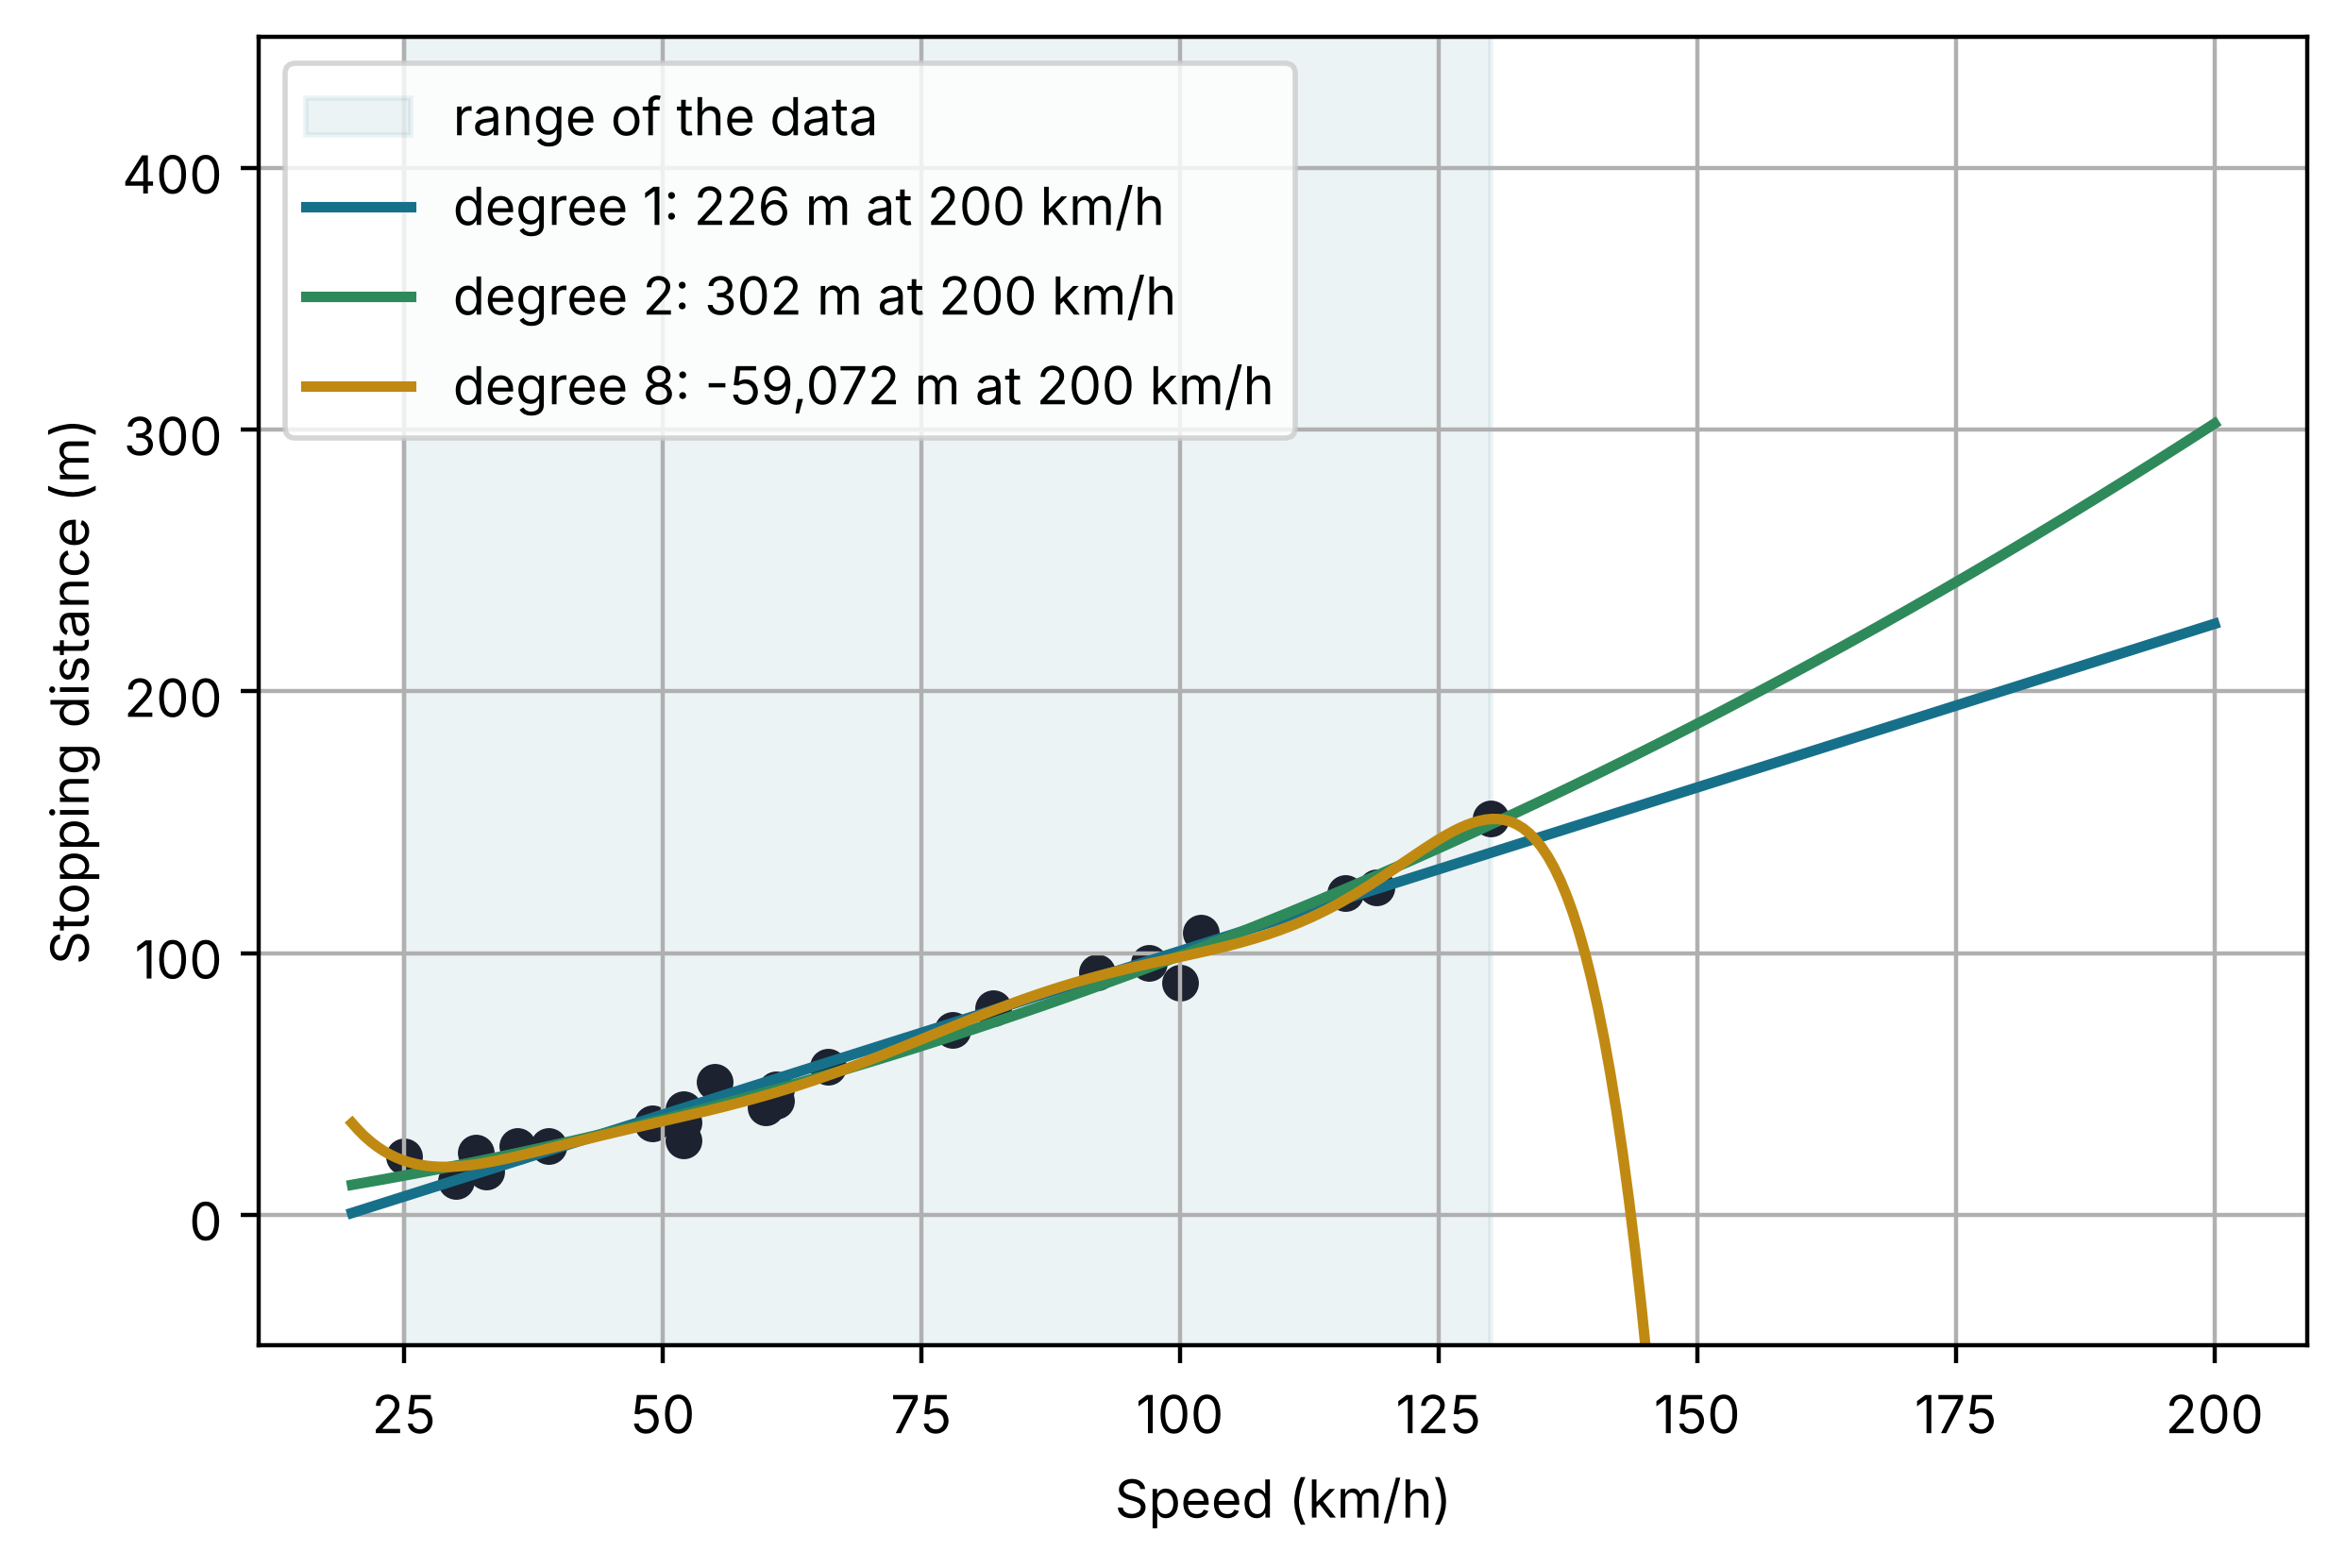

In [13]:
wide = pd.DataFrame({"speed": np.linspace(20, 200, 300)})

plt.axvspan(X["speed"].min(), X["speed"].max(), color="#17708a", alpha=0.08, label="range of the data")
plt.scatter(X["speed"], y, color="#1c2230")
for degree, colour in [(1, "#17708a"), (2, "#2e8a5a"), (8, "#c08a12")]:
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                          StandardScaler(), LinearRegression()).fit(X, y)
    at_200 = model.predict(pd.DataFrame({"speed": [200]}))[0]
    plt.plot(wide["speed"], model.predict(wide), color=colour, linewidth=2,
             label=f"degree {degree}: {at_200:,.0f} m at 200 km/h")
plt.ylim(-50, 450)
plt.xlabel("Speed (km/h)")
plt.ylabel("Stopping distance (m)")
plt.legend()
plt.show()

**Line by line**

1. `wide = pd.DataFrame({"speed": np.linspace(20, 200, 300)})`  
   Speeds from 20 to 200 km/h, far beyond the data.
2. `plt.axvspan(X["speed"].min(), X["speed"].max(), color="#17708a", alpha=0.08, label="range of the data")`  
   Shade the region where we actually have data.
3. `plt.scatter(X["speed"], y, color="#1c2230")`  
   The data.
4. `for degree, colour in [(1, "#17708a"), (2, "#2e8a5a"), (8, "#c08a12")]:`  
   Three degrees again.
5. `model = make_pipeline(PolynomialFeatures(degree, include_bias=False),` …  
   Build and train each one on all the data.
6. `at_200 = model.predict(pd.DataFrame({"speed": [200]}))[0]`  
   Its prediction at 200 km/h.
7. `plt.plot(wide["speed"], model.predict(wide), color=colour, linewidth=2,` …  
   Draw the curve over the wide range, with the 200 km/h prediction in the label.
8. `plt.ylim(-50, 450)`  
   Keep the y-axis readable.
9. `plt.xlabel("Speed (km/h)")` …  
   Labels, key and display.

Inside the shaded region the models roughly agree. Outside it they give wildly different answers, and a high-degree polynomial can even predict a *negative* distance.
**Never trust a polynomial far outside the range of its training data.**

## Summary

| Step | Code |
|---|---|
| Create features | `PolynomialFeatures(degree, include_bias=False)` |
| Scale | `StandardScaler()` |
| Combine | `make_pipeline(features, scaler, LinearRegression())` |
| Choose the degree | `cross_val_score(model, X, y, cv=KFold(5, shuffle=True))` |
| Predict | `model.predict(new_data)` |

## Exercises

1. Change the URL to `.../data/hour_electricity_demand.csv` (columns `hour`, `demand`). Which degree does cross-validation choose? Why is it higher than for stopping distance?
2. In step 6, try `random_state` values 0 to 5. How often does the quadratic beat the line on the test set? What does this tell you about evaluating on only 6 points?
3. In step 9, replace the 5 % rule with simply taking the degree with the lowest CV RMSE. Do you get the same answer? Which would you trust more?
4. Fit degree 2 to `.../data/projectile_height_time.csv`. The physics formula is $h = h_0 + v_0 t - \tfrac{1}{2} g t^2$. Use the $t^2$ coefficient to estimate $g$.
5. Add `Ridge(alpha=1.0)` (from `sklearn.linear_model`) in place of `LinearRegression()` for the degree-10 model. How does its curve change?